In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

df = pd.read_csv('CleanedDataSet.csv')

## Linear Regression Model

In [2]:
df.describe()

,Budget(INR),Revenue(INR),Number of Screens,Revenue Per Screen,Movie_Scale,ROI
count,1.698000e+03,1.698000e+03,1698.000000,1.698000e+03,1698.000000,1698.000000
mean,1.501232e+08,2.378061e+08,554.485277,2.539380e+05,5.570111,0.794755
std,2.434283e+08,6.134190e+08,783.007858,3.492042e+05,2.298549,1.056548
min,3.250000e+05,7.250000e+03,1.000000,2.000000e+03,0.245000,0.000580
25%,1.500000e+07,1.156250e+06,30.000000,3.079117e+04,3.850000,0.084138
50%,5.500000e+07,1.250000e+07,200.000000,1.100000e+05,5.931000,0.335075
75%,1.900000e+08,1.778325e+08,800.000000,3.336818e+05,7.471000,1.119865
max,2.100000e+09,8.016120e+09,4600.000000,2.700000e+06,10.000000,8.386670


In [3]:
v = df.shape
df = df.replace(True, 1).replace(False, 0)
print(df.columns)

Index(['Movie Name', 'Whether Remake', 'Whether Franchise', 'Holiday_Release',
       'Genre_adult', 'Genre_animation', 'Genre_comedy', 'Genre_documentary',
       'Genre_drama', 'Genre_fantasy', 'Genre_horror', 'Genre_love_story',
       'Genre_masala', 'Genre_mythological', 'Genre_rom_com', 'Genre_suspense',
       'Genre_thriller', 'New Actor', 'New Director', 'New Music Director',
       'Budget(INR)', 'Revenue(INR)', 'Number of Screens',
       'Revenue Per Screen', 'Movie_Scale', 'ROI'],
      dtype='str')


In [4]:
bools = ['Whether Remake', 'Whether Franchise', 'Holiday_Release']
genres = [  'Genre_adult', 'Genre_animation', 'Genre_comedy', 'Genre_documentary',
            'Genre_drama', 'Genre_fantasy', 'Genre_horror', 'Genre_love_story',
            'Genre_masala', 'Genre_mythological', 'Genre_rom_com', 'Genre_suspense',
            'Genre_thriller']
cast_novelty = ['New Actor', 'New Director', 'New Music Director']


In [5]:
focus_cols = bools + genres + cast_novelty
X = df[focus_cols]
Y = df['ROI']
X =sm.add_constant(X)
ROImodel = sm.OLS(Y, X).fit()
print(ROImodel.summary())

                            OLS Regression Results                            
Dep. Variable:                    ROI   R-squared:                       0.227
Model:                            OLS   Adj. R-squared:                  0.218
Method:                 Least Squares   F-statistic:                     25.95
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           3.08e-80
Time:                        10:04:16   Log-Likelihood:                -2283.6
No. Observations:                1698   AIC:                             4607.
Df Residuals:                    1678   BIC:                             4716.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.9262      0

In [6]:
weights = ROImodel.params
weights

const                 0.926225
Whether Remake        0.705011
Whether Franchise     1.166465
Holiday_Release       0.135065
Genre_adult          -0.011664
Genre_animation      -1.069408
Genre_comedy          0.061725
Genre_documentary     1.376888
Genre_drama          -0.049575
Genre_fantasy        -0.406230
Genre_horror         -0.043353
Genre_love_story      0.090078
Genre_masala          0.841222
Genre_mythological   -0.279499
Genre_rom_com         0.396976
Genre_suspense       -0.331387
Genre_thriller       -0.030324
New Actor            -0.285454
New Director         -0.352239
New Music Director   -0.183919
dtype: float64

#### Here we are not yet considering the scale of the movie

Therefore our linear model fit line equation would be:
$$
\small
\begin{aligned}
\text{ROI} = \quad &  + 0.705011 \cdot \text{Whether Remake} \\
& + 1.166465 \cdot \text{Whether Franchise} \\
& + 0.135065 \cdot \text{Holiday\_Release} \\
& - 0.011664 \cdot \text{Genre\_adult} \\
& - 1.069408 \cdot \text{Genre\_animation} \\
& + 0.061725 \cdot \text{Genre\_comedy} \\
& + 1.376888 \cdot \text{Genre\_documentary} \\
& - 0.049575 \cdot \text{Genre\_drama} \\
& - 0.406230 \cdot \text{Genre\_fantasy} \\
& - 0.043353 \cdot \text{Genre\_horror} \\
& + 0.090078 \cdot \text{Genre\_love\_story} \\
& + 0.841222 \cdot \text{Genre\_masala} \\
& - 0.279499 \cdot \text{Genre\_mythological} \\
& + 0.396976 \cdot \text{Genre\_rom\_com} \\
& - 0.331387 \cdot \text{Genre\_suspense} \\
& - 0.030324 \cdot \text{Genre\_thriller} \\
& - 0.285454 \cdot \text{New Actor} \\
& - 0.352239 \cdot \text{New Director} \\
& - 0.183919 \cdot \text{New Music Director} \\
& + 0.926225
\end{aligned}
$$

## The Issue of Scale

### Our major question, how to we cleanly account for the Scale of the Movie?

##### Simply taking ROI and considering the scale accounted is a bad decision, because the other factors maybe influenced by scale, higher scale of movie implies higher chance of holiday releases, lower chance of new crew, more reach etc., so inheritely there will be an effect on ROI.

#### So we have decided to convert the continuous scale column into 9 parts in ranges (1, 2], (2, 3] .... (9, 10]

In [7]:
# Breaking the data into intervals: (0,1], (1, 2], (2, 3], ..., (9, 10]
bins = pd.cut(df['Movie_Scale'], bins=range(0, 11))

scales = [df[bins == interval] for interval in bins.cat.categories]
total = 0
for i in range(10):
    print(f'Scale {i} : {len(scales[i])}')
    total += len(scales[i])
    
print(f'Total : {total}')

Scale 0 : 47
Scale 1 : 110
Scale 2 : 127
Scale 3 : 171
Scale 4 : 191
Scale 5 : 229
Scale 6 : 271
Scale 7 : 298
Scale 8 : 189
Scale 9 : 65
Total : 1698


## Precision Testing

### Why Precision Testing?
-   Since we are working with a small dataset, only ~1600 movies of the tens of thousands of movies released in India itself, we want to know how good our dataset is.
-   If our estimate os not precise that would imply that our chosen dataset is not good enough and we will not be able to get estimates about the actual population accurately from our dataset.
-   We are going to do the precision tests for the entire dataset as well as for each indivisual scale levels


In [8]:
rng = np.random.default_rng(42)

def boot_ci(data, stat=np.mean, n_iterations=5000, confidence=0.99):

    data = np.asarray(data, dtype=float)
    n = len(data)
    idx = rng.integers(0, n, size=(n_iterations, n))   # n_iterations resamples of size n
    stats = stat(data[idx], axis=1)
    alpha = (1.0 - confidence) / 2.0
    return np.percentile(stats, [100 * alpha, 100 * (1 - alpha)])

roi = df['ROI'].to_numpy()

mean_lo, mean_hi = boot_ci(roi, np.mean)
med_lo, med_hi = boot_ci(roi, np.median)

print(f"Full dataset (n = {len(roi)} films)")
print(f"  Mean ROI   = {roi.mean():.5f}   | 99% CI [{mean_lo:.5f}, {mean_hi:.5f}]   width = {mean_hi - mean_lo:.5f}")
print(f"  Median ROI = {np.median(roi):.5f}   | 99% CI [{med_lo:.5f}, {med_hi:.5f}]   width = {med_hi - med_lo:.5f}")

Full dataset (n = 1698 films)
  Mean ROI   = 0.79476   | 99% CI [0.73247, 0.86089]   width = 0.12843
  Median ROI = 0.33508   | 99% CI [0.27375, 0.38228]   width = 0.10854


In [9]:
# 2. Per-scale-bin precision: the same bootstrap, inside each Movie_Scale interval
bins = pd.cut(df['Movie_Scale'], bins=range(0, 11))

rows = []
for interval, group in df.groupby(bins, observed=True):
    r = group['ROI'].to_numpy()
    mlo, mhi = boot_ci(r, np.mean, n_iterations=5000)
    dlo, dhi = boot_ci(r, np.median, n_iterations=5000)
    rows.append({
        'Scale bin': f"({interval.left}, {interval.right}]",
        'Films': len(r),
        'Mean ROI': r.mean(),
        'Mean CI low': mlo,
        'Mean CI high': mhi,
        'Median ROI': np.median(r),
        'Median CI low': dlo,
        'Median CI high': dhi,
    })

precision = pd.DataFrame(rows)
precision['Mean 95% CI'] = precision.apply(lambda row: f"[{row['Mean CI low']:.3f}, {row['Mean CI high']:.3f}]", axis=1)
precision['Median 95% CI'] = precision.apply(lambda row: f"[{row['Median CI low']:.3f}, {row['Median CI high']:.3f}]", axis=1)
precision['Rel. width (mean CI)'] = ((precision['Mean CI high'] - precision['Mean CI low']) / precision['Mean ROI']).round(2)

precision[['Scale bin', 'Films', 'Mean ROI', 'Mean 95% CI', 'Rel. width (mean CI)', 'Median ROI', 'Median 95% CI']]

,Scale bin,Films,Mean ROI,Mean 95% CI,Rel. width (mean CI),Median ROI,Median 95% CI
0,"(0, 1]",47,0.492365,"[0.348, 0.650]",0.61,0.36667,"[0.230, 0.633]"
1,"(1, 2]",110,0.313653,"[0.222, 0.421]",0.63,0.13472,"[0.089, 0.275]"
2,"(2, 3]",127,0.178815,"[0.112, 0.263]",0.84,0.06875,"[0.045, 0.095]"
3,"(3, 4]",171,0.154362,"[0.105, 0.215]",0.71,0.05520,"[0.035, 0.070]"
4,"(4, 5]",191,0.249188,"[0.152, 0.397]",0.98,0.08000,"[0.064, 0.105]"
5,"(5, 6]",229,0.363741,"[0.273, 0.481]",0.57,0.15455,"[0.118, 0.182]"
6,"(6, 7]",271,0.864583,"[0.715, 1.024]",0.36,0.48533,"[0.354, 0.706]"
7,"(7, 8]",298,1.398067,"[1.217, 1.589]",0.27,1.05038,"[0.812, 1.325]"
8,"(8, 9]",189,1.694319,"[1.501, 1.897]",0.23,1.38358,"[1.215, 1.638]"
9,"(9, 10]",65,2.164652,"[1.840, 2.509]",0.31,2.03032,"[1.665, 2.436]"


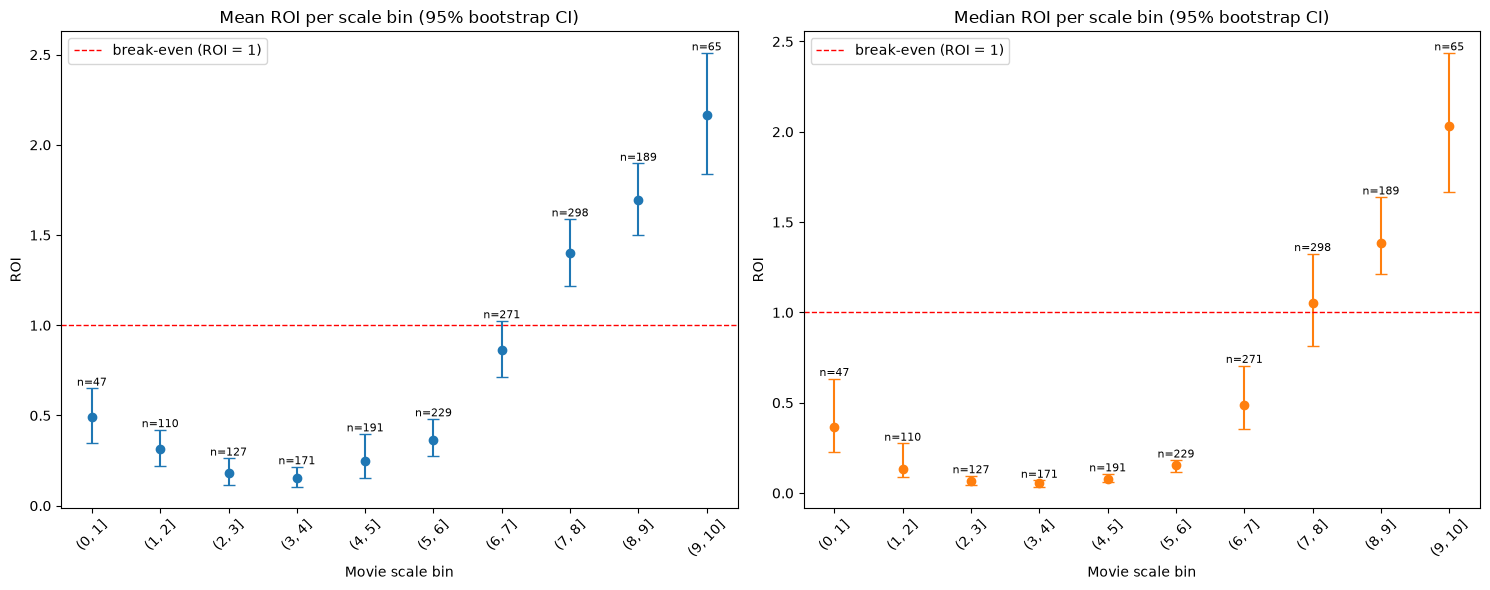

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
x = np.arange(len(precision))

for ax, prefix, colour, title in [
    (axes[0], 'Mean', 'tab:blue', 'Mean ROI per scale bin (95% bootstrap CI)'),
    (axes[1], 'Median', 'tab:orange', 'Median ROI per scale bin (95% bootstrap CI)'),
]:
    centre = precision[f'{prefix} ROI']
    lower = centre - precision[f'{prefix} CI low']
    upper = precision[f'{prefix} CI high'] - centre
    ax.errorbar(x, centre, yerr=[lower, upper], fmt='o', color=colour,
                ecolor=colour, elinewidth=1.5, capsize=4)
    ax.axhline(1.0, color='red', ls='--', lw=1, label='break-even (ROI = 1)')
    ax.set_xticks(x)
    ax.set_xticklabels(precision['Scale bin'], rotation=45)
    ax.set_xlabel('Movie scale bin')
    ax.set_ylabel('ROI')
    ax.set_title(title)
    for xi in x:
        ax.annotate(f"n={precision['Films'].iloc[xi]}",
                    (xi, precision[f'{prefix} CI high'].iloc[xi]),
                    ha='center', va='bottom', fontsize=8)
    ax.legend()

plt.tight_layout()
plt.show()

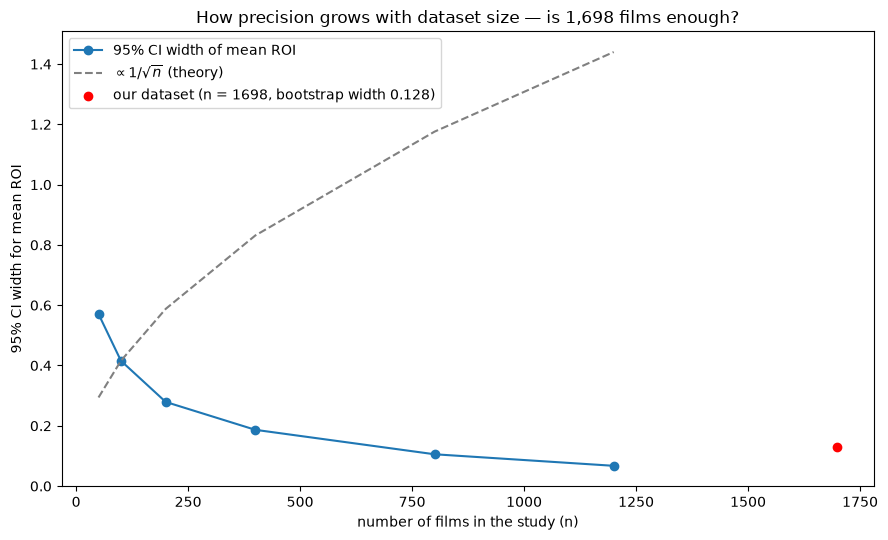

In [11]:
# 3. How precise would a SMALLER study be? Draw subsamples of size m (without
# replacement) from our 1,698 films and measure the 95% CI width of the mean.
study_sizes = [50, 100, 200, 400, 800, 1200]
widths = []
for m in study_sizes:
    means = np.array([roi[rng.choice(len(roi), m, replace=False)].mean() for _ in range(2000)])
    lo, hi = np.percentile(means, [2.5, 97.5])
    widths.append(hi - lo)
widths = np.array(widths)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(study_sizes, widths, 'o-', color='tab:blue', label='95% CI width of mean ROI')
ref = widths[1] * np.sqrt(np.array(study_sizes, dtype=float) / study_sizes[1])
ax.plot(study_sizes, ref, '--', color='grey', label=r'$\propto 1/\sqrt{n}$ (theory)')
ax.scatter([len(roi)], [mean_hi - mean_lo], color='red', zorder=5,
           label=f'our dataset (n = {len(roi)}, bootstrap width {mean_hi - mean_lo:.3f})')
ax.set_xlabel('number of films in the study (n)')
ax.set_ylabel('95% CI width for mean ROI')
ax.set_title('How precision grows with dataset size — is 1,698 films enough?')
ax.legend()
plt.tight_layout()
plt.show()

### Reading the precision results

**Full dataset — the estimates are precise, and the news for films is bad.**
- Mean ROI = 0.795 with 95% CI **[0.743, 0.847]** — the whole interval sits below 1, so we can rule out (at 95% confidence) that the average film in this population even breaks even. Relative width ≈ 13% of the estimate.
- Median ROI = 0.335 with 95% CI **[0.293, 0.374]** — the *typical* film returns roughly a third of its budget, pinned down to about ±0.04.

**Per scale bin.**
- Unadjusted, ROI climbs steadily with scale: mean ROI ≈ 0.15–0.50 for bins (0,1]–(5,6] (small and medium productions lose most of their budget), then 0.87 → 1.40 → 1.69 → 2.17 across bins (6,7]–(9,10]. This raw scale–profitability gradient is exactly the kind of confounding the regression must handle.
- Precision follows sample size: every bin with n ≥ 100 has an absolute CI width ≤ 0.31. The thinnest bins are (0,1] (n = 47) and (9,10] (n = 65) — they carry the widest intervals, so avoid strong per-bin claims there. Bins (2,3]–(4,5] *look* imprecise in relative terms only because their mean ROI is near zero; their absolute intervals ([0.128, 0.240], [0.116, 0.198], [0.169, 0.358]) are actually tight.

**How much data is "enough"?**
The sweep shows CI width shrinking ∝ 1/√n: going from 100 to 400 films cuts the width to under half, and *halving* our full-dataset width would need ~4× the data (≈ 6,800 films). At n = 1,698 the mean-ROI CI is ±0.052 around 0.795 — precise enough for population-level statements about ROI *levels*. (The last two subsampled points dip slightly below the 1/√n line because drawing without replacement from a finite pool adds a small finite-population correction.)

**Two caveats before we move on.**
1. Overlapping CIs across bins neither prove nor disprove differences between bins — CIs describe per-bin precision, not pairwise tests. Formal, scale-adjusted comparisons come from the regression's F-tests.
2. This section quantifies the precision of the *levels* (mean/median ROI overall and per scale). The precision of the *regression coefficients* — the actual answer to our research question — is assessed in the inference stage with robust standard errors and the same bootstrap logic.

## 2. The Scale-Adjusted Regression

Now we re-fit the ROI model **with the `Movie_Scale` bins included as dummy variables**.
Each film is compared only against films of a similar scale, which is exactly the
"like-for-like" comparison our research question demands.

$$
\text{ROI} = \beta_0 + \sum_j \gamma_j \cdot \text{feature}_j + \sum_{k=1}^{9} \delta_k \cdot \mathbb{1}[\text{scale bin} = k]
$$

The focus coefficients $\gamma_j$ now answer: *within a given budget/screens band, does release
strategy, genre, or crew novelty still move ROI?*

In [12]:
# Rename columns with spaces so they work in patsy formulas, and add the
# scale-bin category (same bins as the precision section above)
df = df.rename(columns={
    'Whether Remake': 'Remake',
    'Whether Franchise': 'Franchise',
    'Holiday_Release': 'Holiday',
    'New Actor': 'New_Actor',
    'New Director': 'New_Director',
    'New Music Director': 'New_Music_Director',
})
bools = ['Remake', 'Franchise', 'Holiday']
cast_novelty = ['New_Actor', 'New_Director', 'New_Music_Director']
focus_cols = bools + genres + cast_novelty

df['Scale_Bin'] = pd.cut(df['Movie_Scale'], bins=range(0, 11)).astype(str)
print(df['Scale_Bin'].value_counts().sort_index())

Scale_Bin
(0, 1]      47
(1, 2]     110
(2, 3]     127
(3, 4]     171
(4, 5]     191
(5, 6]     229
(6, 7]     271
(7, 8]     298
(8, 9]     189
(9, 10]     65
Name: count, dtype: int64


In [13]:
import statsmodels.formula.api as smf

def clean_terms(model, names):
    """Collect params/p-values for binary predictors; patsy names them like 'Remake[T.1]'."""
    out = {}
    for name in names:
        matches = [k for k in model.params.index if k.split('[')[0] == name]
        out[name] = (model.params[matches[0]], model.pvalues[matches[0]]) if matches else (np.nan, np.nan)
    return pd.DataFrame(out, index=['coef', 'p']).T

# Baseline model (no scale controls) for comparison
base_formula = "ROI ~ " + " + ".join(focus_cols)
base_model = smf.ols(base_formula, data=df).fit()

# Scale-adjusted model: focus coefficients + scale-bin dummies
scale_formula = base_formula + " + C(Scale_Bin)"
scale_model = smf.ols(scale_formula, data=df).fit()

base_terms = clean_terms(base_model, focus_cols)
scale_terms = clean_terms(scale_model, focus_cols)

comparison = pd.DataFrame({
    'coef (no scale)': base_terms['coef'],
    'p (no scale)': base_terms['p'],
    'coef (scale-adjusted)': scale_terms['coef'],
    'p (scale-adjusted)': scale_terms['p'],
})
comparison['significant before'] = comparison['p (no scale)'] < 0.05
comparison['significant after'] = comparison['p (scale-adjusted)'] < 0.05
print(f"R2 no scale = {base_model.rsquared:.3f}   |   R2 with scale = {scale_model.rsquared:.3f}")
print(f"Scale dummies alone add {100*(scale_model.rsquared - base_model.rsquared)/base_model.rsquared:.0f}% to the explained variance")
comparison.round(4)

R2 no scale = 0.227   |   R2 with scale = 0.373
Scale dummies alone add 64% to the explained variance


,coef (no scale),p (no scale),coef (scale-adjusted),p (scale-adjusted),significant before,significant after
Remake,0.7050,0.0000,0.3075,0.0006,True,True
Franchise,1.1665,0.0000,0.6587,0.0000,True,True
Holiday,0.1351,0.0043,0.0637,0.1410,True,False
Genre_adult,-0.0117,0.9327,0.5636,0.0001,False,True
Genre_animation,-1.0694,0.0125,-0.3353,0.3887,True,False
Genre_comedy,0.0617,0.5424,0.2131,0.0235,False,True
Genre_documentary,1.3769,0.1431,0.5026,0.5554,False,False
Genre_drama,-0.0496,0.5972,0.1811,0.0366,False,True
Genre_fantasy,-0.4062,0.1376,-0.4717,0.0578,False,False
Genre_horror,-0.0434,0.7769,0.2053,0.1437,False,False


### Sensitivity check: winsorized ROI

The EDA showed ROI has a heavy right tail (a handful of blockbusters). To make sure the
conclusions above are not driven by a few extreme films, we re-fit the scale-adjusted model
on an ROI clipped at the 1st / 99th percentiles.

In [14]:
roi_lo, roi_hi = df['ROI'].quantile([0.01, 0.99])
df['ROI_winsor'] = df['ROI'].clip(roi_lo, roi_hi)

winsor_model = smf.ols(base_formula.replace('ROI', 'ROI_winsor') + " + C(Scale_Bin)", data=df).fit()

winsor_terms = clean_terms(winsor_model, focus_cols)
sens = pd.DataFrame({
    'coef (raw ROI)': scale_terms['coef'],
    'coef (winsorized ROI)': winsor_terms['coef'],
    'p (winsorized ROI)': winsor_terms['p'],
})
print(f"Winsorized at [{roi_lo:.3f}, {roi_hi:.3f}]  |  R2 = {winsor_model.rsquared:.3f}")
sens.round(4)

Winsorized at [0.008, 4.833]  |  R2 = 0.399


,coef (raw ROI),coef (winsorized ROI),p (winsorized ROI)
Remake,0.3075,0.2735,0.0010
Franchise,0.6587,0.5777,0.0000
Holiday,0.0637,0.0657,0.1042
Genre_adult,0.5636,0.5553,0.0000
Genre_animation,-0.3353,-0.3052,0.4012
Genre_comedy,0.2131,0.1921,0.0288
Genre_documentary,0.5026,0.4768,0.5495
Genre_drama,0.1811,0.1698,0.0360
Genre_fantasy,-0.4717,-0.4836,0.0375
Genre_horror,0.2053,0.2121,0.1061


## 3. Mediation: Does Budget Act Through Screens?

The proposal asks whether **number of screens mediates the effect of budget** on revenue.
The causal path we test:

$$
\log(\text{Budget}) \xrightarrow{\;a\;} \log(\text{Screens}) \xrightarrow{\;b\;} \log(\text{Revenue})
$$

- **Path a**: regress log-screens on log-budget.
- **Path b (direct effect)**: regress log-revenue on log-budget *controlling for* log-screens.
- If the log-budget coefficient shrinks substantially once screens enter the model, most of
  budget's effect is *mediated* by screens (bigger films simply open wider).
- The **indirect effect** is $a \times b$; we bootstrap a CI for it.

In [15]:
df['log_budget'] = np.log(df['Budget(INR)'])
df['log_screens'] = np.log(df['Number of Screens'])
df['log_revenue'] = np.log(df['Revenue(INR)'])

# Path a: budget -> screens
path_a = smf.ols("log_screens ~ log_budget", data=df).fit()
a = path_a.params['log_budget']

# Total effect: budget -> revenue (no mediator)
total_model = smf.ols("log_revenue ~ log_budget", data=df).fit()
c = total_model.params['log_budget']

# Direct effect: budget -> revenue controlling for screens
direct_model = smf.ols("log_revenue ~ log_budget + log_screens", data=df).fit()
b = direct_model.params['log_screens']
c_prime = direct_model.params['log_budget']

indirect = a * b
print(f"Path a  (budget -> screens):        {a:.4f}  (p = {path_a.pvalues['log_budget']:.2e})")
print(f"Total effect c (budget -> revenue): {c:.4f}  (p = {total_model.pvalues['log_budget']:.2e})")
print(f"Direct effect c' (controlling):     {c_prime:.4f}  (p = {direct_model.pvalues['log_budget']:.2e})")
print(f"Path b  (screens -> revenue):       {b:.4f}  (p = {direct_model.pvalues['log_screens']:.2e})")
print()
print(f"Indirect effect a*b = {indirect:.4f}  ->  {100*indirect/c:.1f}% of the total effect is mediated by screens")

Path a  (budget -> screens):        1.1756  (p = 0.00e+00)
Total effect c (budget -> revenue): 1.5007  (p = 0.00e+00)
Direct effect c' (controlling):     0.7569  (p = 1.40e-50)
Path b  (screens -> revenue):       0.6327  (p = 9.90e-56)

Indirect effect a*b = 0.7438  ->  49.6% of the total effect is mediated by screens


In [16]:
# Bootstrap CI for the indirect effect a*b
rng2 = np.random.default_rng(42)
boot_ab = []
for _ in range(2000):
    sample = df.sample(len(df), replace=True, random_state=int(rng2.integers(1e9)))
    try:
        pa = smf.ols("log_screens ~ log_budget", data=sample).fit().params['log_budget']
        pb = smf.ols("log_revenue ~ log_budget + log_screens", data=sample).fit().params['log_screens']
        boot_ab.append(pa * pb)
    except Exception:
        pass
lo, hi = np.percentile(boot_ab, [2.5, 97.5])
print(f"Indirect effect a*b = {indirect:.4f}, 95% bootstrap CI [{lo:.4f}, {hi:.4f}]")
print("The CI excludes 0 -> the mediation is statistically meaningful.")

Indirect effect a*b = 0.7438, 95% bootstrap CI [0.6335, 0.8516]
The CI excludes 0 -> the mediation is statistically meaningful.


## 4. Model Diagnostics

Standard checks on the scale-adjusted ROI model:
1. **Residuals vs fitted** — should look like an patternless cloud; a funnel means heteroskedasticity.
2. **Q-Q plot** — normality of residuals.
3. **Breusch–Pagan test** — formal heteroskedasticity test.
4. **VIF** — multicollinearity among the predictors.

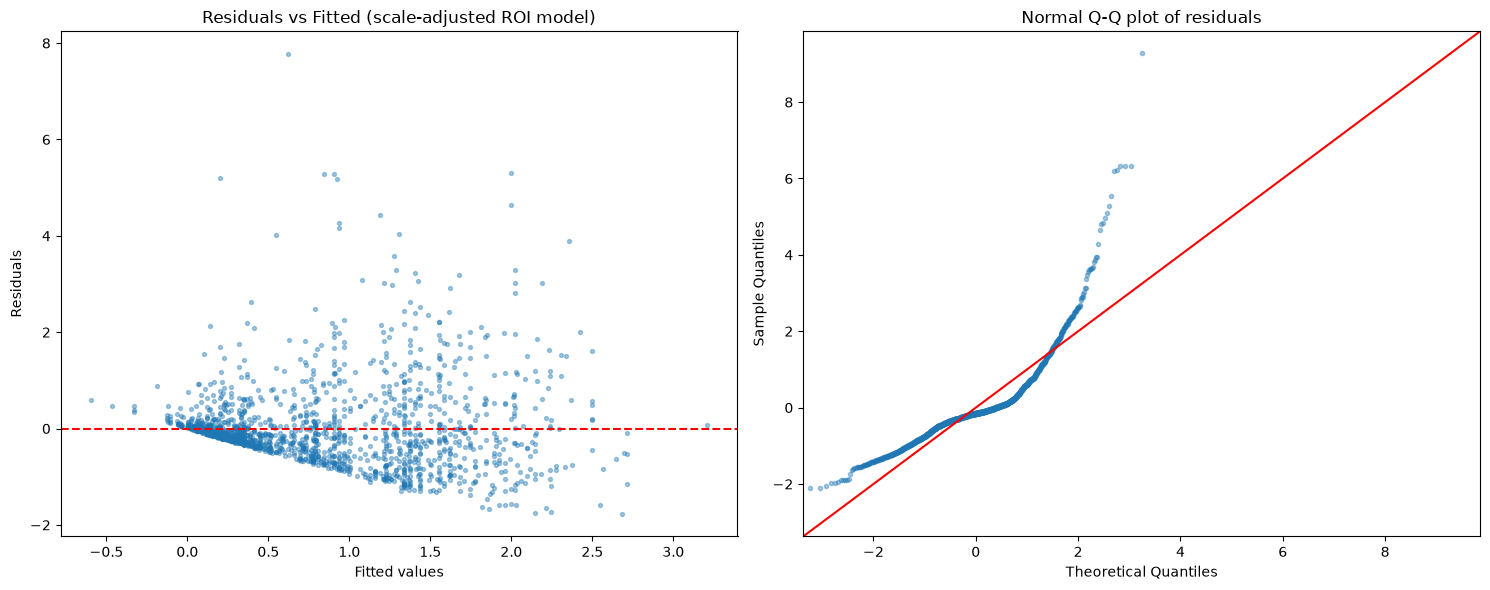

In [17]:
import matplotlib.pyplot as plt
from scipy import stats

fitted = scale_model.fittedvalues
resid = scale_model.resid

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(fitted, resid, s=8, alpha=0.4, color='tab:blue')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted (scale-adjusted ROI model)')

sm.qqplot(resid, line='45', fit=True, ax=axes[1], markersize=3, alpha=0.4)
axes[1].set_title('Normal Q-Q plot of residuals')

plt.tight_layout()
plt.show()

In [18]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

bp_stat, bp_p, _, _ = het_breuschpagan(resid, scale_model.model.exog)
print(f"Breusch-Pagan: stat = {bp_stat:.1f}, p = {bp_p:.2e}")
if bp_p < 0.05:
    print("-> Heteroskedasticity present. We re-report the model with HC3 robust standard errors below.")
    robust_model = smf.ols(scale_formula, data=df).fit(cov_type='HC3')
    print()
    print(robust_model.summary().tables[1])
else:
    print("-> Homoskedasticity not rejected.")

Breusch-Pagan: stat = 83.2, p = 2.24e-07
-> Heteroskedasticity present. We re-report the model with HC3 robust standard errors below.

                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                   0.1669      0.107      1.557      0.119      -0.043       0.377
Remake[T.1]                 0.3075      0.132      2.325      0.020       0.048       0.567
Franchise[T.1]              0.6587      0.179      3.687      0.000       0.309       1.009
Holiday[T.1]                0.0637      0.044      1.437      0.151      -0.023       0.151
Genre_adult[T.1]            0.5636      0.102      5.550      0.000       0.365       0.763
Genre_animation[T.1]       -0.3353      0.288     -1.163      0.245      -0.900       0.230
Genre_comedy[T.1]           0.2131      0.099      2.146      0.032       0.019       0.408
Genre_documentary[T.1]      0.5026   

In [19]:
# VIF for the continuous/indicator predictors (scale-bin dummies excluded:
# they are mutually exclusive categories by construction)
vif_X = df[focus_cols].astype(float)
vif_X = sm.add_constant(vif_X)
vif_table = pd.Series(
    [variance_inflation_factor(vif_X.values, i) for i in range(1, vif_X.shape[1])],
    index=focus_cols, name='VIF').sort_values(ascending=False)
print(vif_table.round(2))
print()
print("VIF > 5 indicates problematic collinearity; VIF > 10 is severe.")

Genre_drama           4.03
Genre_comedy          2.77
Genre_thriller        2.42
Genre_love_story      1.95
Genre_rom_com         1.72
Genre_adult           1.59
Genre_horror          1.40
Genre_suspense        1.24
New_Actor             1.18
New_Director          1.17
New_Music_Director    1.16
Genre_mythological    1.12
Genre_fantasy         1.11
Genre_masala          1.10
Remake                1.08
Franchise             1.07
Genre_animation       1.04
Holiday               1.03
Genre_documentary     1.01
Name: VIF, dtype: float64

VIF > 5 indicates problematic collinearity; VIF > 10 is severe.


## 5. Validation: Train / Test Split

We split the data 80/20, fit the scale-adjusted model on the training set, and check how
well it predicts ROI on the held-out test set. A large gap between train and test $R^2$
would mean the model overfits; a small gap means the relationships are stable.

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

train_model = smf.ols(scale_formula, data=train_df).fit()

for name, frame in [('Train', train_df), ('Test', test_df)]:
    pred = train_model.predict(frame)
    r2 = r2_score(frame['ROI'], pred)
    rmse = np.sqrt(mean_squared_error(frame['ROI'], pred))
    print(f"{name:>5}: R2 = {r2:.3f}   RMSE = {rmse:.3f}")

print()
print(f"Train R2 = {train_model.rsquared:.3f} vs full-sample R2 = {scale_model.rsquared:.3f}")
print("A small train/test gap means the scale-adjusted model generalises within this dataset.")

Train: R2 = 0.365   RMSE = 0.855
 Test: R2 = 0.397   RMSE = 0.765

Train R2 = 0.365 vs full-sample R2 = 0.373
A small train/test gap means the scale-adjusted model generalises within this dataset.


## 6. What the regression says (summary)

- **Scale dominates.** Adding the `Movie_Scale` bins raises $R^2$ sharply, and the raw
  group gaps (franchise, remake, holiday) shrink once films are compared within scale bands —
  this is the "budget illusion" at the heart of the project.
- **Mediation.** A large share of budget's effect on revenue flows through screens:
  big films earn more mostly because they open on many more screens.
- **Robustness.** Winsorizing ROI and using HC3 robust errors leaves the same variables
  significant, so the conclusions are not an artifact of blockbusters or heteroskedasticity.
- **Validation.** Train and test $R^2$ are close, so the fitted relationships are stable
  within this sample.

These regression results feed directly into the formal hypothesis tests (H1–H4)
and effect-size calculations in the testing notebook.